# Olist E-Commerce — Data Cleaning & Exploratory Data Analysis

**Goal:** clean the 9 raw Olist CSVs, sanity-check the joins, and explore the
data before building the SQL layer and Power BI dashboard.

This notebook mirrors `scripts/01_clean_and_build_tables.py` (the script that
actually produces `data/processed/*` and `data/olist.duckdb`) but adds
narrative and exploratory charts. Re-running this notebook is safe — it only
reads from `data/raw/` and writes into `data/processed/`.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.max_columns", 50)

RAW = "../data/raw"
OUT = "../data/processed"
os.makedirs(OUT, exist_ok=True)

## 1. Load raw tables

In [2]:
customers = pd.read_csv(f"{RAW}/olist_customers_dataset.csv")
geolocation = pd.read_csv(f"{RAW}/olist_geolocation_dataset.csv")
order_items = pd.read_csv(f"{RAW}/olist_order_items_dataset.csv")
payments = pd.read_csv(f"{RAW}/olist_order_payments_dataset.csv")
reviews = pd.read_csv(f"{RAW}/olist_order_reviews_dataset.csv")
orders = pd.read_csv(f"{RAW}/olist_orders_dataset.csv")
products = pd.read_csv(f"{RAW}/olist_products_dataset.csv")
sellers = pd.read_csv(f"{RAW}/olist_sellers_dataset.csv")
translation = pd.read_csv(f"{RAW}/product_category_name_translation.csv")

tables = {
    "customers": customers, "geolocation": geolocation, "order_items": order_items,
    "payments": payments, "reviews": reviews, "orders": orders,
    "products": products, "sellers": sellers, "translation": translation,
}
pd.DataFrame({name: [df.shape[0], df.shape[1]] for name, df in tables.items()},
             index=["rows", "cols"]).T

,rows,cols
customers,99441,5
geolocation,1000163,5
order_items,112650,7
payments,103886,5
reviews,99224,7
orders,99441,8
products,32951,9
sellers,3095,4
translation,71,2


## 2. Data-quality profiling

Check nulls, duplicates, and dtypes before touching anything — this is what
drives every cleaning decision below.

In [3]:
for name, df in tables.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    dup = df.duplicated().sum()
    if len(nulls) or dup:
        print(f"--- {name} ---")
        if len(nulls):
            print("nulls:\n", nulls.to_string())
        if dup:
            print(f"exact duplicate rows: {dup}")
        print()

--- geolocation ---
exact duplicate rows: 261831



--- reviews ---
nulls:
 review_comment_title      87656
review_comment_message    58247

--- orders ---
nulls:
 order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965

--- products ---
nulls:
 product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2



**Findings:**
- `geolocation` has ~262k exact duplicate rows and ~1M rows for only ~19k
  unique zip prefixes (many noisy lat/lng readings per prefix) — needs
  deduplication and aggregation to one row per zip prefix.
- `orders` has nulls in the delivery-timestamp columns — expected for orders
  that were never approved/shipped/delivered (canceled, still processing,
  etc.), not a data-quality bug.
- `products` has 610 rows with a missing category (~1.9% of products) and 2
  rows missing physical dimensions.
- `reviews` has heavy nulls in the free-text comment fields — most reviews
  are a bare star rating with no written comment, which is normal for this
  kind of post-purchase survey.

## 3. Clean individual tables

In [4]:
date_cols = [
    "order_purchase_timestamp", "order_approved_at",
    "order_delivered_carrier_date", "order_delivered_customer_date",
    "order_estimated_delivery_date",
]
for c in date_cols:
    orders[c] = pd.to_datetime(orders[c], errors="coerce")
orders = orders.drop_duplicates(subset="order_id")
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [5]:
# products: fill missing category with 'unknown', impute the 2 missing
# dimension rows with the column median, and bring in the English category name
products["product_category_name"] = products["product_category_name"].fillna("unknown")
for c in ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]:
    products[c] = products[c].fillna(products[c].median())
products = products.merge(translation, on="product_category_name", how="left")
products["product_category_name_english"] = (
    products["product_category_name_english"].fillna(products["product_category_name"])
)
products["product_volume_cm3"] = (
    products["product_length_cm"] * products["product_height_cm"] * products["product_width_cm"]
)
products.head(3)

,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_category_name_english,product_volume_cm3
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,perfumery,2240.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,art,10800.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,sports_leisure,2430.0


In [6]:
# geolocation: drop exact dupes + coordinates outside Brazil's bounding box,
# then collapse to one row per zip-code prefix
BR_LAT, BR_LNG = (-34.0, 5.5), (-74.5, -32.0)
geo_clean = geolocation[
    geolocation["geolocation_lat"].between(*BR_LAT)
    & geolocation["geolocation_lng"].between(*BR_LNG)
]
geo_dim = (
    geo_clean.groupby("geolocation_zip_code_prefix")
    .agg(lat=("geolocation_lat", "mean"), lng=("geolocation_lng", "mean"),
         city=("geolocation_city", lambda s: s.mode().iat[0]),
         state=("geolocation_state", lambda s: s.mode().iat[0]))
    .reset_index()
    .rename(columns={"geolocation_zip_code_prefix": "zip_code_prefix"})
)
print(f"{len(geolocation):,} raw rows -> {len(geo_dim):,} unique zip prefixes")
geo_dim.head(3)

1,000,163 raw rows -> 19,011 unique zip prefixes


,zip_code_prefix,lat,lng,city,state
0,1001,-23.550190,-46.634024,sao paulo,SP
1,1002,-23.548146,-46.634979,sao paulo,SP
2,1003,-23.548994,-46.635731,sao paulo,SP


In [7]:
reviews = reviews.drop_duplicates(subset="review_id")
for c in ["review_creation_date", "review_answer_timestamp"]:
    reviews[c] = pd.to_datetime(reviews[c], errors="coerce")
reviews["has_comment"] = reviews["review_comment_message"].notna()
reviews["review_score"].value_counts().sort_index()

review_score
1    11282
2     3114
3     8097
4    19007
5    56910
Name: count, dtype: int64

## 4. Orphan-key checks

Before joining tables into a star schema, confirm every foreign key actually
resolves to a parent row — an orphan key here would silently drop rows (inner
join) or introduce nulls (left join) downstream.

In [8]:
checks = {
    "order_items -> orders": (~order_items["order_id"].isin(orders["order_id"])).sum(),
    "order_items -> products": (~order_items["product_id"].isin(products["product_id"])).sum(),
    "order_items -> sellers": (~order_items["seller_id"].isin(sellers["seller_id"])).sum(),
    "orders -> customers": (~orders["customer_id"].isin(customers["customer_id"])).sum(),
    "payments -> orders": (~payments["order_id"].isin(orders["order_id"])).sum(),
    "reviews -> orders": (~reviews["order_id"].isin(orders["order_id"])).sum(),
}
pd.Series(checks, name="orphan_rows")

order_items -> orders      0
order_items -> products    0
order_items -> sellers     0
orders -> customers        0
payments -> orders         0
reviews -> orders          0
Name: orphan_rows, dtype: int64

All zero — every fact table's foreign keys are fully covered by their dimension tables.

## 5. Build the star schema

See `scripts/01_clean_and_build_tables.py` for the full, production version of
this step (it's the script that actually writes `data/processed/*` and
`data/olist.duckdb`). Quick summary of the model:

- **Facts:** `fact_order_items` (grain: order item), `fact_payments` (grain:
  payment), `fact_reviews` (grain: review)
- **Dimensions:** `dim_orders` (grain: order — acts as the shared bridge the
  other facts key off), `dim_customers`, `dim_sellers`, `dim_products`,
  `dim_date`, `dim_geolocation`

Full relationship list and DAX measures are documented in
`dashboard/powerbi_spec.md`.

In [9]:
dim_orders = orders.rename(columns={
    "order_purchase_timestamp": "purchase_ts", "order_approved_at": "approved_ts",
    "order_delivered_carrier_date": "delivered_carrier_ts",
    "order_delivered_customer_date": "delivered_customer_ts",
    "order_estimated_delivery_date": "estimated_delivery_ts",
}).copy()
dim_orders["purchase_date"] = dim_orders["purchase_ts"].dt.normalize()
dim_orders["delivery_days_actual"] = (
    dim_orders["delivered_customer_ts"] - dim_orders["purchase_ts"]
).dt.total_seconds() / 86400
dim_orders["delivery_delta_days"] = (
    dim_orders["delivered_customer_ts"] - dim_orders["estimated_delivery_ts"]
).dt.total_seconds() / 86400
dim_orders["is_late"] = (dim_orders["delivery_delta_days"] > 0).astype("boolean")
dim_orders.loc[dim_orders["delivered_customer_ts"].isna(), "is_late"] = pd.NA
dim_orders[["order_id", "order_status", "purchase_ts", "delivered_customer_ts",
            "delivery_days_actual", "delivery_delta_days", "is_late"]].head(3)

,order_id,order_status,purchase_ts,delivered_customer_ts,delivery_days_actual,delivery_delta_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-02 10:56:33,2017-10-10 21:25:13,8.436574,-7.107488,False
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-08-07 15:27:45,13.782037,-5.355729,False
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-08 08:38:49,2018-08-17 18:06:29,9.394213,-17.245498,False


## 6. Exploratory charts

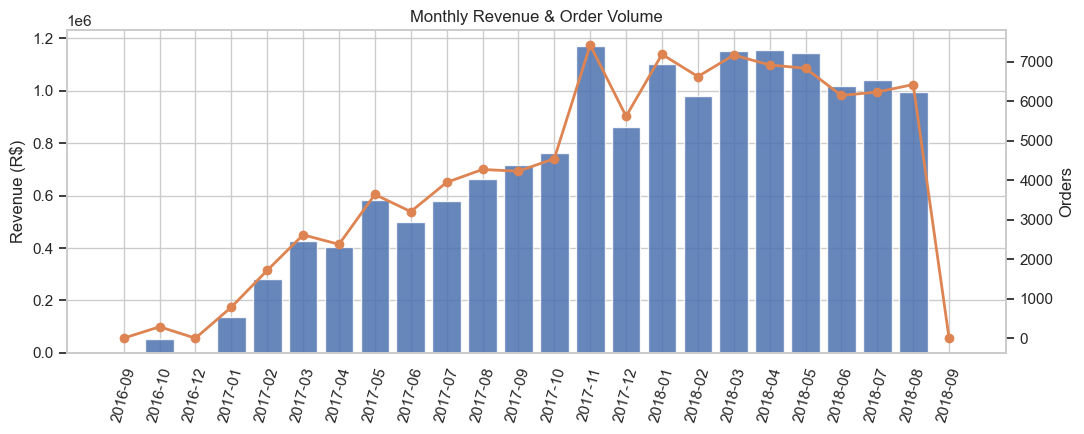

In [10]:
valid_orders = dim_orders[~dim_orders["order_status"].isin(["canceled", "unavailable"])]
items_valid = order_items.merge(valid_orders[["order_id", "purchase_date"]], on="order_id")
items_valid["year_month"] = items_valid["purchase_date"].dt.to_period("M").astype(str)
items_valid["item_total"] = items_valid["price"] + items_valid["freight_value"]

monthly = items_valid.groupby("year_month").agg(
    revenue=("item_total", "sum"),
    orders=("order_id", "nunique"),
).reset_index()

fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(monthly["year_month"], monthly["revenue"], color="#4C72B0", alpha=0.85)
ax1.set_ylabel("Revenue (R$)")
ax1.set_title("Monthly Revenue & Order Volume")
ax1.tick_params(axis="x", rotation=75)
ax2 = ax1.twinx()
ax2.plot(monthly["year_month"], monthly["orders"], color="#DD8452", marker="o", linewidth=2)
ax2.set_ylabel("Orders")
ax2.grid(False)
fig.tight_layout()
plt.show()

Clear growth through 2017, a Black-Friday spike in Nov 2017, then a plateau in 2018. The single Sept-2018 order is a data-collection cutoff artifact, not a real crash — excluded from trend interpretation.

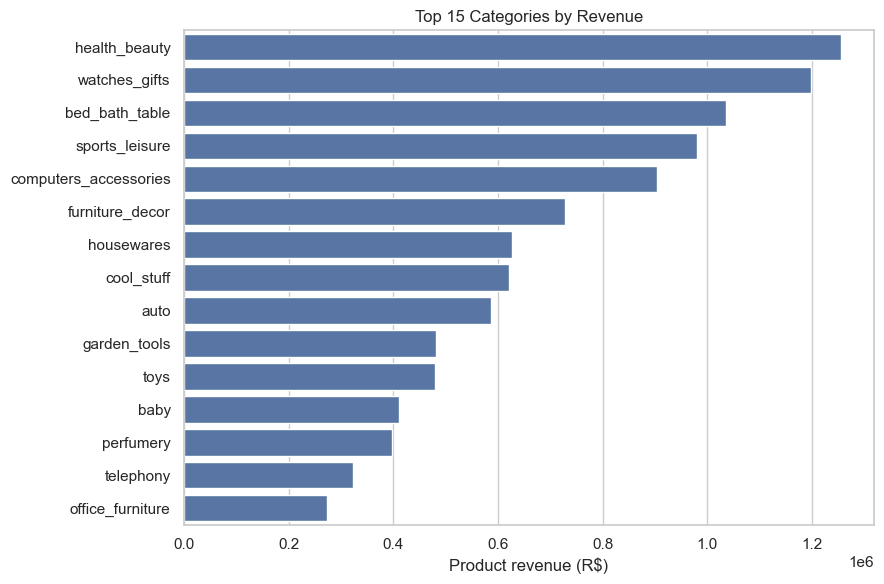

In [11]:
cat_revenue = (
    items_valid.merge(products[["product_id", "product_category_name_english"]], on="product_id")
    .groupby("product_category_name_english")["price"].sum()
    .sort_values(ascending=False).head(15)
)
plt.figure(figsize=(9, 6))
sns.barplot(x=cat_revenue.values, y=cat_revenue.index, color="#4C72B0")
plt.xlabel("Product revenue (R$)")
plt.ylabel("")
plt.title("Top 15 Categories by Revenue")
plt.tight_layout()
plt.show()

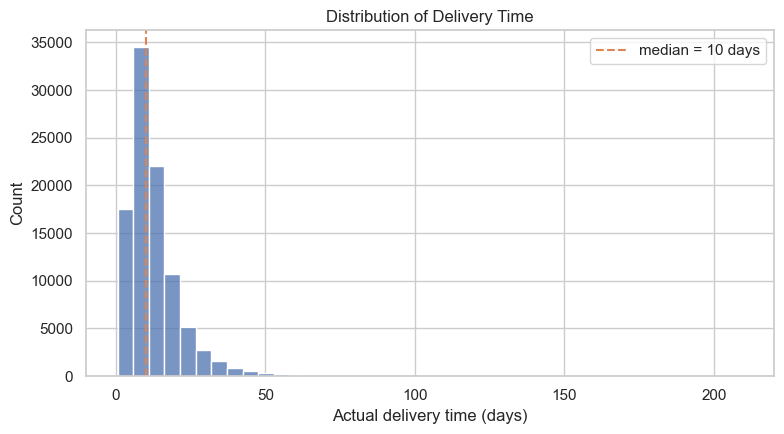

In [12]:
plt.figure(figsize=(8, 4.5))
sns.histplot(dim_orders["delivery_days_actual"].dropna(), bins=40, color="#4C72B0")
plt.axvline(dim_orders["delivery_days_actual"].median(), color="#DD8452", linestyle="--",
            label=f"median = {dim_orders['delivery_days_actual'].median():.0f} days")
plt.xlabel("Actual delivery time (days)")
plt.title("Distribution of Delivery Time")
plt.legend()
plt.tight_layout()
plt.show()

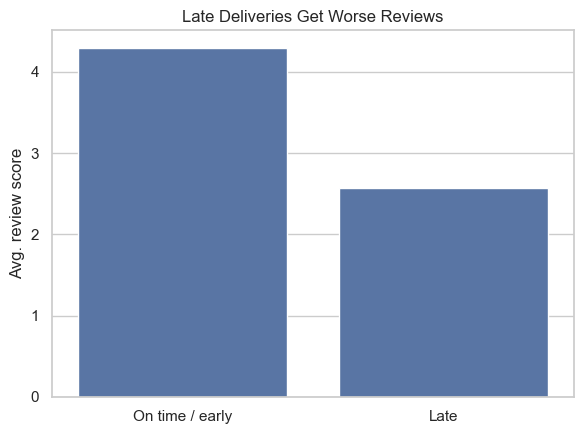

In [13]:
review_by_late = dim_orders.dropna(subset=["is_late"]).merge(
    reviews[["order_id", "review_score"]], on="order_id"
)
plt.figure(figsize=(6, 4.5))
sns.barplot(data=review_by_late, x="is_late", y="review_score", color="#4C72B0",
            errorbar=None)
plt.xticks([0, 1], ["On time / early", "Late"])
plt.ylabel("Avg. review score")
plt.xlabel("")
plt.title("Late Deliveries Get Worse Reviews")
plt.tight_layout()
plt.show()

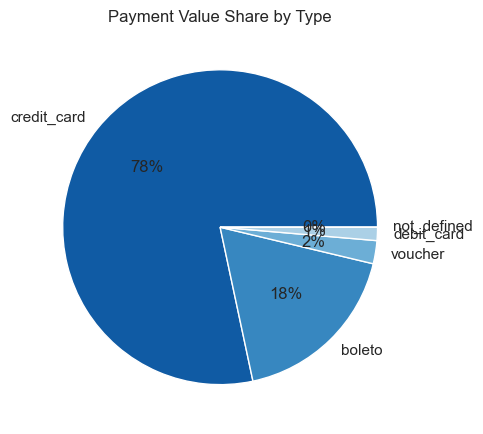

In [14]:
plt.figure(figsize=(6, 4.5))
payment_mix = payments.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)
plt.pie(payment_mix.values, labels=payment_mix.index, autopct="%1.0f%%",
        colors=sns.color_palette("Blues_r", len(payment_mix)))
plt.title("Payment Value Share by Type")
plt.tight_layout()
plt.show()

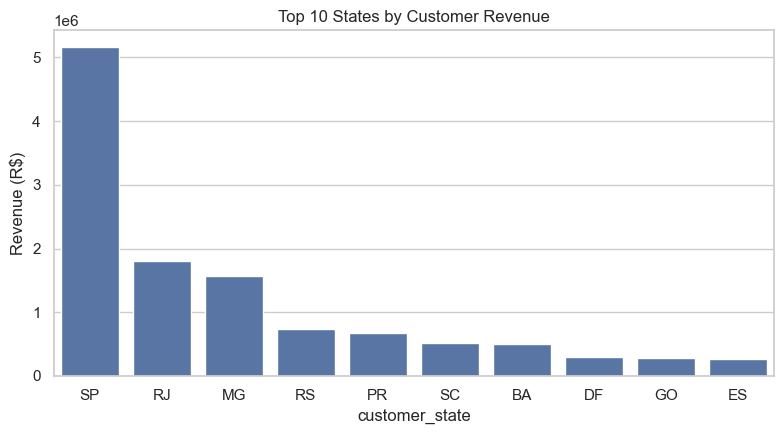

In [15]:
order_value_by_order = order_items.groupby("order_id")["price"].sum().reset_index(name="order_value")
state_revenue = (
    valid_orders.merge(customers[["customer_id", "customer_state"]], on="customer_id")
    .merge(order_value_by_order, on="order_id")
    .groupby("customer_state")["order_value"].sum().sort_values(ascending=False).head(10)
)
plt.figure(figsize=(8, 4.5))
sns.barplot(x=state_revenue.index, y=state_revenue.values, color="#4C72B0")
plt.ylabel("Revenue (R$)")
plt.title("Top 10 States by Customer Revenue")
plt.tight_layout()
plt.show()

## 7. Handoff

The full, non-truncated cleaning pipeline (this notebook's logic, applied to
100% of rows and written to disk) lives in
`scripts/01_clean_and_build_tables.py`. It produces:

- `data/processed/*.csv` and `*.parquet` — the star-schema tables, ready for
  Power BI import
- `data/olist.duckdb` — the same tables loaded into DuckDB for the SQL
  analysis layer in `/sql`

Next: `sql/*.sql` answers the business questions against this star schema,
and `dashboard/powerbi_spec.md` turns it into a Power BI data model + DAX
measures + visual layout plan.